# Homework 1: probability through simulation

**Scientific Computing 2026 · Probability and multivariate distributions**

Eight coding problems with mathematical derivations. Tasks 1–4 cover Lectures
1 and 2; Tasks 5–8 extend the homework to the multivariate material.
Work in this notebook:
write each derivation in its Markdown answer cell, implement the requested
functions, and add your experiments and plots. Finish each task with a short
interpretation. No training of machine-learning models is required.

You only need basic Python: variables, `if`, `for`/`while`, lists, and functions.
**No previous NumPy, pandas, SciPy, or Matplotlib experience is assumed.**
Short runnable examples introduce the library features immediately before you
need them. Try changing their numbers and predicting the new output.

Plotting and table templates are provided.
Ordinary Python loops are welcome: compact or fast array code earns no extra credit.
Pandas is only used to display tables; no pandas data manipulation is required.
The restrictions on random generators in Tasks 1 and 3 remain part of the questions.

The function stubs intentionally raise `NotImplementedError` when called.
They are not called until you enable the corresponding entry in `RUN_TASKS`.
This lets you complete and check one task without implementing the others.
A clean run of the starter does **not** mean the homework has been completed.

**Submission:** one completed notebook with derivations, code, saved outputs,
and interpretations. Restart the kernel and run all cells before submitting.

## Getting started: a small Python toolkit

Run a cell with **Shift+Enter**. Code cells execute Python; Markdown cells hold
text and formulas. Double-click a Markdown answer cell to edit it, then run it
to render the text. For example, type `$\mathbb E[X]$` for $\mathbb E[X]$.
Run cells from top to bottom: Python remembers the variables in earlier cells.
If you get `NameError`, check whether the defining cell was run.

The setup cell imports four tools: `np` is NumPy (arrays and random draws),
`pd` is pandas (tables), `plt` is Matplotlib (plots), and SciPy supplies familiar
probability functions. An `import` makes these tools available; it does not
generate any data. If an import fails, follow the installation instructions
in this folder's README and select that environment as the notebook kernel.

Run the setup unchanged except for the two controls at the end of the student
copy. `RUN_TASKS` is a dictionary mapping each task number to an on/off value.
The setup creates entries for Tasks 1–8, initially all `False`.
To run only Task 5, change its entry from `5: False` to `5: True`, leaving
the other entries unchanged. You can enable several tasks as they become ready.
After changing a control, rerun the setup cell so Python sees its new value.
`QUICK_RUN = True` reduces the experiment sizes while you debug; set it to
`False` for the requested full experiments. Checks use fixed test sizes.
The plot styling and the supplied `empirical_cdf`, `observed_moments`, and
`show_table` helpers are support code, not functions you need to implement.
`empirical_cdf(samples, grid)` efficiently evaluates the fraction of observations
at or below each grid value. The sorting inside it is not part of this homework.
Read the comments in the supplied experiment templates; you may adapt their
plots and tables. Enable a task only after replacing its `NotImplementedError`
lines. The checks run when that task is enabled. An `assert` raises
`AssertionError` when its condition is false: read the failing line to see
which property failed. You do not need to write this checking syntax yourself.
The checks test selected properties; still provide your derivation and
interpretation.


In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import binom, norm, poisson, gamma
from IPython.display import display

%matplotlib inline

BLUE, ORANGE, TEAL, INK = "#1F4E79", "#C46A13", "#007D80", "#16324F"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4),
    "font.size": 11, "axes.titlesize": 12,
    "axes.labelsize": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.18, "legend.frameon": False,
})
pd.set_option("display.precision", 6)


def empirical_cdf(samples, grid):
    '''Fraction of one-dimensional samples that are <= each grid value.'''
    samples = np.asarray(samples, dtype=float)
    if samples.ndim != 1 or samples.size == 0:
        raise ValueError("samples must be a nonempty one-dimensional array")
    return np.searchsorted(np.sort(samples), grid, side="right") / samples.size


def observed_moments(samples):
    '''Empirical moments, using the empirical distribution (ddof=0).'''
    return float(np.mean(samples)), float(np.var(samples, ddof=0))


def show_table(rows):
    '''Each dictionary is one row; its keys become column names.'''
    display(pd.DataFrame(rows))


# Enable a task only when its function scaffolds have been completed.
RUN_TASKS = {1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False, 8: False}
QUICK_RUN = True  # Small debugging runs; set False for your final submission.

### 1. Lists, arrays, and proportions

A NumPy **array** stores numbers on which we can calculate element by element.
`np.array(...)` converts a Python list to an array. A list's `+` concatenates;
an array's `+` adds numbers. `shape` tells us its dimensions: `(4,)` means four
entries in one dimension. Indexing starts at zero, so `x[0]` is the first entry.

A comparison produces an array of `True`/`False` values, called a **mask**.
`x[mask]` selects the matching entries. In a mean, `True` counts as 1 and `False`
as 0, so `np.mean(x > threshold)` is the fraction above that threshold.
`np.var(x, ddof=0)` computes the average squared distance from the sample mean,
with denominator $n$, as required here. We are describing the empirical
distribution, not asking for an unbiased variance estimator.

In [2]:
numbers = [1.0, 3.0, 6.0, 8.0]
x = np.array(numbers)
print("List + list:", numbers + numbers)
print("Array + array:", x + x)
print("Array shape:", x.shape, "First entry:", x[0])
print("Mask:", x > 4)
print("Selected entries:", x[x > 4])
print("Mean:", np.mean(x), "Variance:", np.var(x, ddof=0))
print("Fraction above 4:", np.mean(x > 4))
# Try changing 4 to 6. Why does the fraction change to 0.25?

List + list: [1.0, 3.0, 6.0, 8.0, 1.0, 3.0, 6.0, 8.0]
Array + array: [ 2.  6. 12. 16.]
Array shape: (4,) First entry: 1.0
Mask: [False False  True  True]
Selected entries: [6. 8.]
Mean: 4.5 Variance: 7.25
Fraction above 4: 0.5


### 2. Reproducible randomness and simple tables

`np.random.default_rng(17)` makes a random-number generator with seed 17.
`rng.random(size=5)` draws five independent uniforms on $[0,1)$; `size` is the
number of draws. Recreating a generator with the same seed repeats its sequence.
Calling the **same generator again** advances that sequence instead. Create one
generator before a repetition loop; do not reset it inside every iteration.

For a table, collect ordinary Python dictionaries in a list. Each dictionary
is one row, and its keys are the column names. `show_table(rows)` calls
`pd.DataFrame(rows)` and displays it. You may use `print(rows)` instead: pandas
is a display convenience, not a prerequisite for the probability work.

In [3]:
demo_rng = np.random.default_rng(17)
first_draws = demo_rng.random(size=5)
next_draws = demo_rng.random(size=5)
repeated_draws = np.random.default_rng(17).random(size=5)
print("First:", first_draws)
print("Next:", next_draws)
print("Same seed, new generator:", repeated_draws)
rows = []
rows.append({"sample": "first five", "mean": np.mean(first_draws)})
rows.append({"sample": "next five", "mean": np.mean(next_draws)})
show_table(rows)

First: [0.84507479 0.16097309 0.55774455 0.36807994 0.21494196]
Next: [0.38582404 0.4281645  0.61134311 0.73638587 0.01528966]
Same seed, new generator: [0.84507479 0.16097309 0.55774455 0.36807994 0.21494196]


,sample,mean
0,first five,0.429363
1,next five,0.435401


### 3. A histogram and a theoretical curve

`fig, ax = plt.subplots()` creates a figure and one plotting area. `ax.hist`
draws a histogram; `ax.plot(x, y)` joins the corresponding points with a line.
`np.linspace(a, b, num)` creates `num` equally spaced points including both ends.
For a histogram, those points are **bin edges**, so 11 edges make 10 bins.
With `density=True`, the histogram's total area, rather than its total bar
height, is one. This makes it comparable with a PDF. `ax.legend()` displays
the supplied labels, and `plt.show()` displays the finished figure.

The example below is complete. Try 50 draws and then 5,000: the theoretical
line stays the same, while the histogram changes. Plot templates in each task
reuse these same commands; you do not need to invent plotting code from scratch.

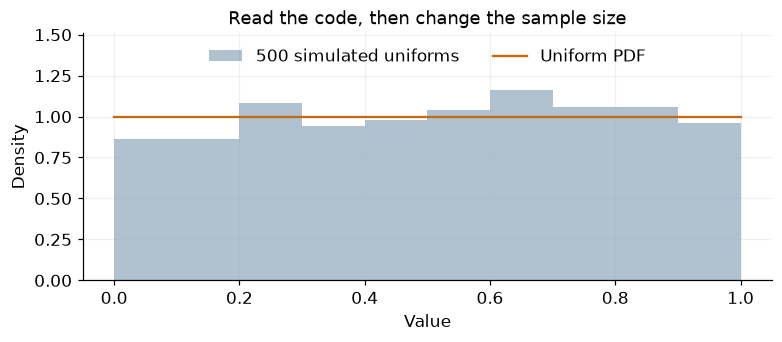

In [4]:
demo_rng = np.random.default_rng(23)
uniform_samples = demo_rng.random(size=500)
edges = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.hist(uniform_samples, bins=edges, density=True, alpha=0.35,
        color=BLUE, label="500 simulated uniforms")
ax.plot([0, 1], [1, 1], color=ORANGE, label="Uniform PDF")
ax.set(xlabel="Value", ylabel="Density", title="Read the code, then change the sample size")
ax.margins(y=0.3)  # Leave space above the data for the legend.
ax.legend(loc="upper center", ncol=2)
plt.show()

## Part I. Probability through simulation

Tasks 1–4 use the material from Lectures 1 and 2.

## Task 1. Build a sampler from a CDF

The target distribution has cumulative distribution function
$$
F_X(x)=\begin{cases}
0,&x<0,\\
x^2/2,&0\le x<1,\\
1-(2-x)^2/2,&1\le x<2,\\
1,&x\ge2.
\end{cases}
$$

### Theory

1. Derive the PDF and check that it integrates to one.
2. Find $F_X^{-1}(u)$ for $0<u<1$, including the point where its formula
   changes. Use the continuous endpoint values at $u=0,1$ in your code.
3. Prove that $F_X^{-1}(U)$ has CDF $F_X$ when $U\sim\operatorname{Uniform}(0,1)$.
4. Calculate $\mathbb E[X]$, $\operatorname{Var}(X)$, and $\mathbb P(X>1.5)$.

### Code and experiments

Implement `target_cdf`, `target_pdf`, `inverse_cdf`, and `sample_from_cdf`.
The first three should accept a scalar or NumPy array and preserve its shape.
The conversion and array scaffolds below handle this interface for you.
The sampler must use **only uniform random draws**, followed by your inverse.
Do not use a built-in sampler or numerical inverse-CDF routine for the target.

For $n=100,1000,10000,100000$:

- Overlay a density-normalized histogram and the theoretical PDF. Use the same
  bin edges for every sample size.
- Plot the empirical CDF against the target CDF. Here
  $\widehat F_n(x)=n^{-1}\sum_{i=1}^n\mathbf 1\{X_i\le x\}$.
- Tabulate the empirical mean, variance, and fraction above $1.5$, alongside
  the theoretical values. Use `ddof=0` for the empirical variance in this homework.

Repeat each sample size with **20 independent runs**, using a fixed grid of
1001 points in $[0,2]$. Compute $\max_j|\widehat F_n(x_j)-F_X(x_j)|$ for each
run and plot its variation with $n$. This is a **grid-based discrepancy**,
not an exact supremum over every real number and not a hypothesis test.

Explain why increasing $n$ need not improve the agreement in every individual
run. No formal convergence theorem or error bound is required.

### Python lab: translate a piecewise function

The example is a different function, $g(x)=0$ for $x<0$ and $g(x)=x+1$ otherwise.
`np.asarray(x, dtype=float)` accepts a scalar, list, or array and treats it as
numbers. `np.zeros_like(x)` makes a same-shaped array of zeros. On the line
`result[nonnegative] = x[nonnegative] + 1`, the mask selects exactly the entries
to change. For intervals use `(x >= a) & (x < b)`; keep the parentheses and use
`&` rather than Python's `and`. `np.sqrt` takes square roots element by element.

For Task 1, keep the zero-filled entries where your function is zero, then fill
each remaining region using its mask and the formula you derived. Do not alter
the input. You can first check the formulas with scalar Python `if` statements;
the array version below is the pattern to follow for the final interface.

In [5]:
def practice_piecewise(x):
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    nonnegative = x >= 0
    result[nonnegative] = x[nonnegative] + 1
    return result

print(practice_piecewise([-2, 0, 3]))  # [0, 1, 4]
print(practice_piecewise(3.0))         # Scalar input works too.
print(np.sqrt(np.array([0, 1, 9])))
print("ECDF at 2:", empirical_cdf([1, 2, 2, 5], [2]))  # Three out of four.

[0. 1. 4.]
4.0
[0. 1. 3.]
ECDF at 2: [0.75]


### Your derivation

Write your mathematical argument here, before implementing it.

In [6]:
def target_cdf(x):
    '''Evaluate the supplied CDF at x.'''
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    # TODO: make a mask for each region and fill result[mask].
    raise NotImplementedError("Implement the piecewise CDF")
    return result


def target_pdf(x):
    '''Evaluate the density you derived.'''
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    # TODO: fill the regions using your derivative of the CDF.
    raise NotImplementedError("Implement the PDF")
    return result


def inverse_cdf(u):
    '''Evaluate your inverse for 0 <= u <= 1.'''
    u = np.asarray(u, dtype=float)
    result = np.zeros_like(u)
    # TODO: split u at the boundary you derived and fill both regions.
    raise NotImplementedError("Implement the inverse CDF")
    return result


def sample_from_cdf(n, rng):
    '''Return n samples, using rng.uniform or rng.random only.'''
    uniform_draws = rng.random(size=n)
    # TODO: return the inverse-CDF transformation of uniform_draws.
    raise NotImplementedError("Transform uniform draws")


def target_moments():
    '''Return your theoretical mean, variance, and P(X > 1.5), in that order.'''
    raise NotImplementedError("Return three numbers from your derivation")

### Run your experiment

Enable Task 1 with `RUN_TASKS[1] = True` after completing its functions.


In [7]:
if RUN_TASKS[1]:
    # Supplied experiment: concentrate on your probability functions above.
    sample_sizes = [100, 1_000] if QUICK_RUN else [100, 1_000, 10_000, 100_000]
    repeat_count = 3 if QUICK_RUN else 20
    cdf_grid = np.linspace(0, 2, 1001)
    histogram_edges = np.linspace(0, 2, 41)
    rng = np.random.default_rng(202601)
    theory_mean, theory_variance, theory_tail = target_moments()
    rows = [{"n": "theory", "mean": theory_mean, "variance": theory_variance,
             "P(X > 1.5)": theory_tail}]

    # axes[row, column] picks one panel of a rectangular grid of plots.
    fig, axes = plt.subplots(len(sample_sizes), 2, figsize=(11, 3 * len(sample_sizes)),
                             layout="constrained")
    for row, n in enumerate(sample_sizes):  # enumerate gives (position, value).
        samples = sample_from_cdf(n, rng)
        rows.append({"n": n, "mean": np.mean(samples), "variance": np.var(samples),
                     "P(X > 1.5)": np.mean(samples > 1.5)})
        ax = axes[row, 0]
        ax.hist(samples, bins=histogram_edges, density=True, alpha=0.3, label="Samples")
        ax.plot(cdf_grid, target_pdf(cdf_grid), color=ORANGE, label="Target PDF")
        ax.set(xlabel="x", ylabel="Density", title=f"n = {n}")
        ax.legend()
        ax = axes[row, 1]
        ax.plot(cdf_grid, target_cdf(cdf_grid), color=ORANGE, label="Target CDF")
        ax.step(cdf_grid, empirical_cdf(samples, cdf_grid), where="post", label="Empirical CDF")
        ax.set(xlabel="x", ylabel="Probability", title=f"n = {n}")
        ax.legend()
    plt.show()
    show_table(rows)

    # abs -> size of each difference; max -> the largest grid difference.
    repeat_rng = np.random.default_rng(202602)
    median_errors = []
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for n in sample_sizes:
        errors = []
        for repetition in range(repeat_count):
            sample = sample_from_cdf(n, repeat_rng)
            differences = empirical_cdf(sample, cdf_grid) - target_cdf(cdf_grid)
            errors.append(np.max(np.abs(differences)))
        median_errors.append(np.median(errors))
        ax.scatter([n] * repeat_count, errors, color=BLUE, alpha=0.4)
    ax.plot(sample_sizes, median_errors, "o-", color=ORANGE, label="Median discrepancy")
    ax.set(xscale="log", yscale="log", xlabel="Sample size", ylabel="Grid discrepancy")
    ax.legend()
    plt.show()
else:
    print("Task 1: implement the functions, then enable RUN_TASKS[1].")

Task 1: implement the functions, then enable RUN_TASKS[1].


### Your interpretation

How does the grid-based CDF discrepancy vary across sample sizes and independent
runs? Explain why it need not decrease in every run. Compare the histogram
and empirical CDF with their theoretical curves.


### Check your implementation

The checks below test inverse-CDF composition, normalization, support, and
a fixed-seed empirical CDF comparison.


In [8]:
if RUN_TASKS[1]:
    u_check = np.linspace(0, 1, 1001)
    assert np.allclose(target_cdf(inverse_cdf(u_check)), u_check)
    assert np.allclose(target_cdf([-np.inf, 0, 2, np.inf]), [0, 0, 1, 1])
    assert np.all(target_pdf(np.linspace(-1, 3, 1001)) >= 0)
    assert np.isclose(quad(target_pdf, 0, 2, points=[1])[0], 1)
    assert sample_from_cdf(0, np.random.default_rng(10)).shape == (0,)
    check_sample = sample_from_cdf(100_000, np.random.default_rng(9001))
    assert np.all((check_sample >= 0) & (check_sample <= 2))
    check_grid = np.linspace(0, 2, 1001)
    assert np.max(np.abs(empirical_cdf(check_sample, check_grid) - target_cdf(check_grid))) < 0.02
    print("Task 1 checks passed.")
else:
    print("Task 1: checks skipped until your implementation is ready.")

Task 1: checks skipped until your implementation is ready.


## Task 2. Infer a hidden machine condition

A machine produces a batch of ten items. Its unobserved condition is
$Z\sim\operatorname{Bernoulli}(0.2)$, where $Z=1$ means degraded operation.
The number of defective items is
$$K\mid Z=z\sim\operatorname{Binomial}(10,p_z),\qquad p_0=0.05,\quad p_1=0.35.$$
A sensor reports a noisy estimate of this count:
$$Y\mid K=k\sim\mathcal N(k,\sigma^2),\qquad \sigma=1.5.$$
Given $K$, the reading does not depend further on $Z$. The model is the chain
$$\underbrace{Z}_{\text{machine condition}}\longrightarrow
\underbrace{K}_{\text{defect count}}\longrightarrow
\underbrace{Y}_{\text{sensor reading}}.$$
Negative sensor readings are possible: $Y$ is an estimate, not the actual count.

### Theory

1. Derive $\mathbb P(Z=1\mid Y=y)$ by summing over the unknown $K$.
2. Derive $\mathbb P(K=k\mid Y=y)$ and an expression for the posterior expected count.
3. If the exact $K$ were also observed, would $Y$ provide additional information
   about $Z$? Justify your answer using the probability formulas.

Use the Gaussian **density** as the likelihood of a reading. You do not need
MCMC or an inference library: there are only $2\times11$ hidden states.

### Code and experiments

- Implement `simulate_batches(n, rng, sigma=1.5, prior_bad=0.2)`, returning
  one-dimensional arrays `z, k, y`, generated in that order.
- Implement `posterior(y, sigma=1.5, prior_bad=0.2)`, returning a normalized
  array of shape `(2, 11)`. Entry `[z, k]` represents
  $\mathbb P(Z=z,K=k\mid Y=y)$. Use your explicit Bayes formula, not an inference package.
  Assume a finite scalar `y`, `sigma > 0`, and `0 < prior_bad < 1`.
- Simulate at least 100,000 batches. Visualize the sensor readings for each
  machine condition and compare with their conditional density models.
- For $Y=4$, report the posterior probability of degradation and the posterior
  expected defect count. Plot the prior and posterior PMFs of $K$.
- Plot $\mathbb P(Z=1\mid Y=y)$ as a function of $y$ for
  $\sigma=0.5,1.5,3$, keeping the same prior. Explain the effect of sensor noise.

Start with two ordinary loops over `z` and `k`: only 22 states are possible.
You may use `binom.pmf` and `norm.pdf` to evaluate the known distributions;
you still need to derive and implement the Bayes weights and their normalization.
You do not need broadcasting, matrix multiplication, or logarithmic arithmetic.
The required reading range is $-10\le y\le20$ with the three stated noise
levels. Handling extremely unlikely readings beyond this range is optional.

### Python lab: draws, probabilities, and a two-dimensional array

`rng.binomial(n=6, p=0.25, size=5)` draws five counts from six-trial binomials.
For a Bernoulli draw use `n=1`. In `rng.normal(loc=2, scale=0.7, size=5)`,
`loc` is the mean and `scale` is the **standard deviation**, not the variance.
Omit `size` when you want one draw. These calls generate random observations.

In contrast, `binom.pmf(k, n, p)` evaluates $\mathbb P(K=k)$ and
`norm.pdf(y, loc=mu, scale=sd)` evaluates a Gaussian density. Neither draws
random numbers. These functions work on scalars, so simple loops are enough.

`np.zeros((2, 3))` creates a table with two rows and three columns. In the toy
table below, `weights[1, 2]` means row 1, column 2. `np.sum(weights)` adds all
entries. Dividing the entire table by that sum normalizes nonnegative weights.
`np.sum(table, axis=0)` sums **down the rows**, giving one value per column;
`axis=1` sums **across columns**, giving one value per row. Try the explicit
row calculation below before using `axis` in the experiment template.

In [9]:
demo_rng = np.random.default_rng(31)
print("Binomial draws:", demo_rng.binomial(n=6, p=0.25, size=5))
print("Gaussian draws:", demo_rng.normal(loc=2, scale=0.7, size=5))
print("Binomial P(K=2):", binom.pmf(2, n=6, p=0.25))
print("Gaussian density at y=2:", norm.pdf(2, loc=2, scale=0.7))

weights = np.array([[1.0, 2.0, 1.0], [2.0, 1.0, 3.0]])
table = weights / np.sum(weights)
print("Normalized toy table:\n", table)
print("Column sums:", np.sum(table, axis=0))
print("Row sums:", np.sum(table, axis=1))
print("Second row total:", table[1, 0] + table[1, 1] + table[1, 2])

Binomial draws: [3 0 2 1 2]
Gaussian draws: [2.17854069 2.54808591 2.19069276 2.81340569 1.34357053]
Binomial P(K=2): 0.2966308593750001
Gaussian density at y=2: 0.5699175434306182
Normalized toy table:
 [[0.1 0.2 0.1]
 [0.2 0.1 0.3]]
Column sums: [0.3 0.3 0.4]
Row sums: [0.4 0.6]
Second row total: 0.6000000000000001


The following helper is supplied for the histogram overlay. It evaluates the
conditional density of a reading by adding the eleven possible count
contributions. Here `np.zeros_like` makes space for a whole curve, and each
iteration adds one weighted Gaussian curve. Read the sum as the law of total
probability. The Bayesian update itself is still for you to implement.

Debug your simulator with `n=5` and print `z, k, y` first. Each position must
describe the **same batch**: draw its condition, then use that condition to
choose the binomial probability, then use that count as the Gaussian mean.

In [10]:
def conditional_reading_density(readings, condition, sigma=1.5):
    readings = np.asarray(readings, dtype=float)
    density = np.zeros_like(readings)
    defect_probability = 0.05 if condition == 0 else 0.35
    for count in range(11):
        count_probability = binom.pmf(count, n=10, p=defect_probability)
        density += count_probability * norm.pdf(readings, loc=count, scale=sigma)
    return density

### Your derivation

Write your mathematical argument here, before implementing it.

In [11]:
def simulate_batches(n, rng, sigma=1.5, prior_bad=0.2):
    '''Return arrays (z, k, y), each of shape (n,).'''
    z = np.zeros(n, dtype=int)
    k = np.zeros(n, dtype=int)
    y = np.zeros(n)
    for i in range(n):
        # TODO: fill z[i], choose p based on z[i], fill k[i], then y[i].
        raise NotImplementedError("Generate one batch's condition, count, and reading")
    return z, k, y


def posterior(y, sigma=1.5, prior_bad=0.2):
    '''Return a (2, 11) array of posterior probabilities for (Z, K).'''
    weights = np.zeros((2, 11))
    for z in range(2):
        for k in range(11):
            # TODO: fill weights[z, k] with your unnormalized Bayes weight.
            raise NotImplementedError("Combine the model factors for this state")
    # TODO: normalize all 22 weights and return the probability table.
    raise NotImplementedError("Normalize the table")

### Run your experiment

Enable Task 2 with `RUN_TASKS[2] = True` after completing its functions.


In [12]:
if RUN_TASKS[2]:
    k_values = np.arange(11)
    reading_grid = np.linspace(-3, 12, 301)
    n = 1_000 if QUICK_RUN else 100_000
    z, k, readings = simulate_batches(n, np.random.default_rng(202603))
    edges = np.linspace(min(-6, readings.min()), max(15, readings.max()), 70)
    curve_grid = np.linspace(edges[0], edges[-1], 401)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for condition in [0, 1]:
        ax = axes[condition]
        # The mask selects readings from batches in this condition only.
        ax.hist(readings[z == condition], bins=edges, density=True, alpha=0.3, label="Simulation")
        ax.plot(curve_grid, conditional_reading_density(curve_grid, condition),
                color=ORANGE, label="Conditional density")
        ax.set(xlabel="Sensor reading", ylabel="Density", title=f"Z = {condition}")
        ax.legend()
    plt.show()

    post = posterior(4.0)
    posterior_k = np.sum(post, axis=0)  # One probability per column, hence per count.
    prior_k = 0.8 * binom.pmf(k_values, 10, 0.05) + 0.2 * binom.pmf(k_values, 10, 0.35)
    show_table([{"P(Z=1 | Y=4)": np.sum(post[1]),
                 "E[K | Y=4]": np.sum(k_values * posterior_k)}])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    axes[0].bar(k_values - 0.2, prior_k, width=0.4, label="Prior")
    axes[0].bar(k_values + 0.2, posterior_k, width=0.4, color=ORANGE, label="Posterior")
    axes[0].set(xlabel="Defect count", ylabel="Probability", xticks=k_values)
    axes[0].legend()
    for sigma in [0.5, 1.5, 3.0]:
        probabilities = []
        for reading in reading_grid:
            state_table = posterior(reading, sigma=sigma)
            probabilities.append(np.sum(state_table[1]))
        axes[1].plot(reading_grid, probabilities, label=f"Sensor SD = {sigma}")
    axes[1].axhline(0.2, color=INK, linestyle=":", label="Prior")
    axes[1].set(xlabel="Reading y", ylabel="P(Z=1 | Y=y)")
    axes[1].legend()
    plt.show()
else:
    print("Task 2: implement the functions, then enable RUN_TASKS[2].")

Task 2: implement the functions, then enable RUN_TASKS[2].


### Your interpretation

How does increasing sensor noise change the posterior curves for the machine
condition? Explain why rounding the sensor reading to a defect count would
change the inference. If the exact count were known, would the reading add
information about the condition?


### Check your implementation

The checks below test posterior shape and normalization, valid defect counts,
and conditional simulation means.


In [13]:
if RUN_TASKS[2]:
    for y_value in [-10, 0, 4, 10, 20]:
        p_check = posterior(y_value)
        assert p_check.shape == (2, 11)
        assert np.all(np.isfinite(p_check)) and np.all(p_check >= 0)
        assert np.isclose(p_check.sum(), 1)

    z_check, k_check, y_check = simulate_batches(100_000, np.random.default_rng(9002))
    assert z_check.shape == k_check.shape == y_check.shape == (100_000,)
    assert np.all(np.isin(z_check, [0, 1])) and np.all((k_check >= 0) & (k_check <= 10))
    assert abs(z_check.mean() - 0.2) < 0.01
    assert abs(k_check[z_check == 0].mean() - 10 * 0.05) < 0.05
    assert abs(k_check[z_check == 1].mean() - 10 * 0.35) < 0.1
    print("Task 2 checks passed.")
else:
    print("Task 2: checks skipped until your implementation is ready.")

Task 2: checks skipped until your implementation is ready.


## Task 3. One arrival process, three distributions

Requests arrive with independent exponential gaps at rate
$\lambda=0.8$ requests per minute. The process starts at time zero, with no
request already present. Write $N(5)$ for the number of arrivals in the first
five minutes, and $T_4$ for the time of the fourth arrival.

### Theory

1. Identify the distributions of $N(5)$ and $T_4$, stating all parameters.
2. Calculate their means and variances, with units.
3. Explain why $\{T_4\le5\}=\{N(5)\ge4\}$ and calculate the probability of
   this event using Poisson probabilities.

### Code and experiments

Implement `simulate_arrival_path(rng, rate=0.8, horizon=5.0, kth=4)`.
Return the increasing array of arrival times. Generate independent exponential
gaps and accumulate them. Continue until you have both observed the fourth
arrival **and** generated an arrival after the five-minute observation window.
Use no arbitrary fixed cap on the number of arrivals.

Then implement `simulate_arrivals(n, rng, rate=0.8, horizon=5.0, kth=4)`.
Return arrays `counts, kth_times`, each of length `n`. Obtain both quantities
from the **same simulated path** for each repetition.

You may use an exponential random-number generator or your own exponential
inverse transform. **Do not directly sample Poisson counts or Gamma arrival
times.** NumPy's exponential generator takes a scale, not a rate.

Use at least 30,000 independent paths to:

- Show one arrival timeline with the deadline and fourth arrival marked.
- Compare the empirical count PMF with its theoretical PMF.
- Compare the fourth-arrival histogram with its theoretical density.
- Tabulate the theoretical and empirical means, variances, and deadline probability.
- Check that the two deadline-event indicators agree on **every path**.

Explain why agreement of these indicators is a stronger implementation check
than merely obtaining similar aggregate probabilities.

### Python lab: accumulate gaps and count events

For an exponential distribution, NumPy takes `scale=1/rate`, measured here
in minutes. With no `size`, `rng.exponential(scale=...)` returns one gap.
Use an ordinary Python list while the number of arrivals is unknown; `append`
adds the next arrival time. Convert the finished list with `np.array`.

The toy example below uses three fixed gaps, **not random ones**. It shows how
to update a running clock and count the times at or below a deadline using a
mask. `np.sum(times <= deadline)` counts `True` entries. The $k$th arrival is
at index `k-1`, because Python indexing starts at zero.

Your actual simulator needs a `while` loop, not a fixed three-iteration loop.
Before writing its condition, answer: when can you stop if the fourth arrival
comes before the deadline? What if it comes after? Test with a few paths before
running thousands. Do not recreate the random generator inside either loop.

In [14]:
fixed_gaps = [0.4, 1.1, 0.8]
arrival_list = []
clock = 0.0
for gap in fixed_gaps:
    clock = clock + gap
    arrival_list.append(clock)
times = np.array(arrival_list)
print("Arrival times:", times)  # [0.4, 1.5, 2.3]
print("Arrivals by time 2:", np.sum(times <= 2.0))
print("Second arrival:", times[2 - 1])
print("One random gap:", np.random.default_rng(41).exponential(scale=1 / 0.8))

# Evaluating a model is different from sampling from it:
print("A Poisson PMF:", poisson.pmf(np.arange(4), mu=2.0))
print("A Gamma density:", gamma.pdf([1.0, 2.0], a=3, scale=1 / 2.0))
# In scipy.stats.gamma, a is the shape and scale is the reciprocal of the rate.

Arrival times: [0.4 1.5 2.3]
Arrivals by time 2: 2
Second arrival: 1.5
One random gap: 6.028193671754783
A Poisson PMF: [0.13533528 0.27067057 0.27067057 0.18044704]
A Gamma density: [0.54134113 0.29305022]


### Your derivation

Write your mathematical argument here, before implementing it.

In [15]:
def simulate_arrival_path(rng, rate=0.8, horizon=5.0, kth=4):
    '''Return arrival times until both the deadline and kth arrival are resolved.'''
    arrivals = []
    time = 0.0
    # TODO: add a while loop that draws gaps, updates time, and appends arrivals.
    # len(arrivals) tells you how many arrivals have been generated so far.
    raise NotImplementedError("Accumulate independent exponential gaps")
    return np.array(arrivals)


def simulate_arrivals(n, rng, rate=0.8, horizon=5.0, kth=4):
    '''Return arrays of counts by the horizon and times of the kth arrival.'''
    counts = np.zeros(n, dtype=int)
    kth_times = np.zeros(n)
    for i in range(n):
        arrivals = simulate_arrival_path(rng, rate, horizon, kth)
        # TODO: fill counts[i] and kth_times[i] using this same path.
        raise NotImplementedError("Extract the count and the kth arrival time")
    return counts, kth_times


def arrival_moments(rate=0.8, horizon=5.0, kth=4):
    '''Return E[N], Var(N), E[T_k], Var(T_k), and P(T_k <= horizon).'''
    # TODO: translate the formulas from your theory answer into Python.
    raise NotImplementedError("Return the five theoretical quantities")

### Run your experiment

Enable Task 3 with `RUN_TASKS[3] = True` after completing its functions.


In [16]:
if RUN_TASKS[3]:
    path = simulate_arrival_path(np.random.default_rng(202605))
    fig, ax = plt.subplots(figsize=(10, 2.5), layout="constrained")
    ax.vlines(path, 0.3, 0.7, color=BLUE, label="Arrivals")  # One vertical tick per arrival.
    ax.axvline(5, color=ORANGE, linestyle="--", label="Deadline")
    ax.scatter([path[3]], [0.5], color=TEAL, marker="*", s=200, label="Fourth arrival")
    ax.set(xlabel="Time (minutes)", yticks=[], ylim=(0, 1), xlim=(0, max(5, path[-1]) * 1.1))
    ax.legend(loc="upper center", ncol=3)
    plt.show()

    n = 500 if QUICK_RUN else 30_000
    counts, kth_times = simulate_arrivals(n, np.random.default_rng(202604))
    event_from_time = kth_times <= 5
    event_from_count = counts >= 4
    print("Events agree on every path:", np.array_equal(event_from_time, event_from_count))
    theory = arrival_moments()
    observed = [np.mean(counts), np.var(counts), np.mean(kth_times), np.var(kth_times),
                np.mean(event_from_time)]
    names = ["Mean count", "Count variance", "Mean time (min)", "Time variance (min²)",
             "Deadline probability"]
    rows = []
    for i in range(len(names)):
        rows.append({"quantity": names[i], "theory": theory[i], "simulation": observed[i]})
    show_table(rows)

    # For an integer count, the mean of (counts == value) estimates its PMF.
    support = np.arange(np.max(counts) + 1)
    frequencies = []
    for value in support:
        frequencies.append(np.mean(counts == value))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    axes[0].bar(support, frequencies, alpha=0.35, label="Simulation")
    axes[0].plot(support, poisson.pmf(support, mu=0.8 * 5), "o-", color=ORANGE, label="Poisson model")
    axes[0].set(xlabel="Count in five minutes", ylabel="Probability")
    axes[0].legend()
    edges = np.linspace(0, max(20, np.max(kth_times)), 65)
    grid = np.linspace(0, edges[-1], 501)
    axes[1].hist(kth_times, bins=edges, density=True, alpha=0.3, label="Simulation")
    axes[1].plot(grid, gamma.pdf(grid, a=4, scale=1 / 0.8), color=ORANGE, label="Gamma model")
    axes[1].set(xlabel="Fourth-arrival time (minutes)", ylabel="Density (per minute)")
    axes[1].legend()
    plt.show()
else:
    print("Task 3: implement the functions, then enable RUN_TASKS[3].")

Task 3: implement the functions, then enable RUN_TASKS[3].


### Your interpretation

Explain why `T_4 <= 5` and `N(5) >= 4` agree on every simulated path, even
when their estimated probability differs from the theoretical value. How
does your stopping rule ensure both quantities come from the same path?


### Check your implementation

The checks below test the arrival-path stopping rule and the exact agreement
of the two event indicators.


In [17]:
if RUN_TASKS[3]:
    path_check = simulate_arrival_path(np.random.default_rng(9003))
    assert path_check.ndim == 1 and path_check.size >= 4
    assert path_check[-1] > 5
    assert np.all(np.diff(path_check) > 0) and path_check[0] >= 0
    count_check, time_check = simulate_arrivals(2_000, np.random.default_rng(9004))
    assert count_check.shape == time_check.shape == (2_000,)
    assert np.all(count_check >= 0) and np.all(time_check >= 0)
    assert np.array_equal(time_check <= 5, count_check >= 4)
    print("Task 3 checks passed.")
else:
    print("Task 3: checks skipped until your implementation is ready.")

Task 3: checks skipped until your implementation is ready.


## Task 4. Can averaging remove a sensor's error?

A reading's error is $X_i=B_i+\varepsilon_i$, where
$\varepsilon_i\sim\mathcal N(0,1)$. A sensor's calibration offset is $-2$ or
$2$ with equal probability. All reading noises are independent of each other
and of the offsets.

Compare two protocols for an experiment with $m$ readings:

- **Same sensor (`shared`):** select one offset $B$ and use it throughout the
  experiment, so $X_i=B+\varepsilon_i$.
- **Fresh sensor (`fresh`):** independently draw a new offset $B_i$ for each
  reading, so $X_i=B_i+\varepsilon_i$.

Report the average error $\overline X_m=m^{-1}\sum_{i=1}^m X_i$. In the
same-sensor protocol, draw a **new sensor at the beginning of each independent
experiment**, but keep that sensor for all readings within the experiment.

### Theory

1. Show that one reading has the same distribution under both protocols.
   Calculate its mean and variance.
2. Derive the mean and variance of $\overline X_m$ for each protocol.
3. State which variance-addition steps require independence. Explain which
   source of error averaging removes and which can remain.

### Code and experiments

Implement `simulate_sensor_averages(repetitions, m, rng, protocol)`, with
`protocol` equal to `"shared"` or `"fresh"`. Return a one-dimensional array of
average errors, one per independent experiment. Simulate the individual
offsets and reading noises, rather than directly sampling the distribution
of the average.

For $m=1,5,20,100$, simulate at least 20,000 independent experiments under
each protocol. Then:

- Compare histograms of the averages, using common bin edges for both protocols.
- Tabulate empirical means and variances alongside your theoretical values.
- Plot empirical and theoretical variance against $m$.
- Explain why identical distributions for individual readings do not force
  identical distributions for their averages.

These are errors relative to a known reference. A zero average error across
all randomly selected sensors does not mean a particular sensor is unbiased.

### Python lab: one experiment at a time

`rng.choice([-2.0, 2.0])` chooses one value, with equal probabilities by default.
Adding `size=m` chooses `m` values independently. The placement and number of
these draws express an important modeling assumption: does an offset belong
to the entire experiment, or to a single reading?

Start with an ordinary loop over experiments. Inside that loop, simulate one
experiment's `m` readings, compute `np.mean(readings)`, and store it. You do
not need a large two-dimensional array or broadcasting. In the toy example
below, adding a scalar offset to an array adds it to **every entry**.
Using two arrays of equal length instead adds corresponding entries.

First try two experiments with three readings each and print the offsets,
noises, and readings. Only increase the sizes once those small examples match
your intended model. Remember that `repetitions` counts independent experiments,
whereas `m` counts readings inside one experiment.

In [18]:
toy_noise = np.array([0.2, -0.4, 0.1])
print("One offset for all entries:", 1.5 + toy_noise)
toy_offsets = np.array([1.5, -1.5, 1.5])
print("One offset per entry:", toy_offsets + toy_noise)
demo_rng = np.random.default_rng(51)
print("One choice:", demo_rng.choice([-2.0, 2.0]))
print("Three independent choices:", demo_rng.choice([-2.0, 2.0], size=3))

# This is storage practice, not the sensor simulator.
averages = np.zeros(2)
for experiment in range(2):
    toy_readings = demo_rng.normal(loc=0, scale=1, size=3)
    averages[experiment] = np.mean(toy_readings)
print("One average per experiment:", averages)

One offset for all entries: [1.7 1.1 1.6]
One offset per entry: [ 1.7 -1.9  1.6]
One choice: -2.0
Three independent choices: [ 2.  2. -2.]
One average per experiment: [ 0.33627684 -0.04097592]


### Your derivation

Write your mathematical argument here, before implementing it.

In [19]:
def simulate_sensor_averages(repetitions, m, rng, protocol):
    '''Simulate the readings and return one average error per experiment.'''
    averages = np.zeros(repetitions)
    for experiment in range(repetitions):
        # TODO: draw offset(s) according to protocol, then m noises.
        # Construct the m readings and put their average in averages[experiment].
        raise NotImplementedError("Implement one shared or fresh sensor experiment")
    return averages


def sensor_moments(m, protocol):
    '''Return the theoretical (mean, variance) that you derived for the average.'''
    raise NotImplementedError("Implement your theoretical moment formulas")

### Run your experiment

Enable Task 4 with `RUN_TASKS[4] = True` after completing its functions.


In [20]:
if RUN_TASKS[4]:
    reading_counts = [1, 5, 20, 100]
    repetitions = 500 if QUICK_RUN else 20_000
    rng = np.random.default_rng(202606)
    samples = {}  # A dictionary can use a pair (protocol, m) as its key.
    rows = []
    largest_error = 5.0
    for protocol in ["shared", "fresh"]:
        for m in reading_counts:
            values = simulate_sensor_averages(repetitions, m, rng, protocol)
            samples[protocol, m] = values
            largest_error = max(largest_error, np.max(np.abs(values)))
            theory_mean, theory_variance = sensor_moments(m, protocol)
            rows.append({"protocol": protocol, "m": m, "mean": np.mean(values),
                         "theory mean": theory_mean, "variance": np.var(values),
                         "theory variance": theory_variance})
    show_table(rows)

    # Common edges include every simulated reading under both protocols.
    edges = np.linspace(-largest_error - 0.1, largest_error + 0.1, 181)
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for i, m in enumerate(reading_counts):
        ax = axes.flat[i]  # flat lets us visit the four panels in sequence.
        ax.hist(samples["shared", m], bins=edges, density=True, histtype="step",
                color=BLUE, label="Same sensor")
        ax.hist(samples["fresh", m], bins=edges, density=True, histtype="step",
                color=ORANGE, label="Fresh sensors")
        ax.set(xlabel="Average error", ylabel="Density", title=f"m = {m}")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    for protocol in ["shared", "fresh"]:
        theory_variances = []
        empirical_variances = []
        for m in reading_counts:
            theory_mean, theory_variance = sensor_moments(m, protocol)
            theory_variances.append(theory_variance)
            empirical_variances.append(np.var(samples[protocol, m]))
        ax.plot(reading_counts, theory_variances, label=f"{protocol}: theory")
        ax.scatter(reading_counts, empirical_variances, label=f"{protocol}: simulation")
    ax.set(xscale="log", yscale="log", xlabel="Readings per experiment", ylabel="Variance of the average")
    ax.legend()
    plt.show()
else:
    print("Task 4: implement the functions, then enable RUN_TASKS[4].")

Task 4: implement the functions, then enable RUN_TASKS[4].


### Your interpretation

Which part of the shared-sensor error remains as the number of readings grows?
Use your variance formulas to explain the different histogram shapes under
the two protocols, despite identical distributions for individual readings.


### Check your implementation

The checks below compare simulated moments with your formulas and verify
that the two protocols agree in distribution for one reading.


In [21]:
if RUN_TASKS[4]:
    for protocol in ["shared", "fresh"]:
        test_values = simulate_sensor_averages(5_000, 5, np.random.default_rng(9005), protocol)
        assert test_values.shape == (5_000,) and np.all(np.isfinite(test_values))
        mean_theory, variance_theory = sensor_moments(5, protocol)
        assert np.isfinite(mean_theory) and variance_theory >= 0
        assert abs(test_values.mean() - mean_theory) < 0.15
        assert np.isclose(test_values.var(), variance_theory, rtol=0.15, atol=0.05)

    # The distributions coincide at m=1. Valid implementations need not consume
    # random numbers in the same order, so exact sample-by-sample equality is not required.
    one_shared = simulate_sensor_averages(10_000, 1, np.random.default_rng(1234), "shared")
    one_fresh = simulate_sensor_averages(10_000, 1, np.random.default_rng(5678), "fresh")
    assert np.allclose(sensor_moments(1, "shared"), sensor_moments(1, "fresh"))
    assert abs(one_shared.mean() - one_fresh.mean()) < 0.25
    assert np.isclose(one_shared.var(), one_fresh.var(), rtol=0.15)
    print("Task 4 checks passed.")
else:
    print("Task 4: checks skipped until your implementation is ready.")

Task 4: checks skipped until your implementation is ready.


## Part II. Multivariate distributions

Tasks 5–8 extend the first four tasks to random vectors. They assume the
multivariate material from the course: covariance matrices, linear transformations,
and jointly Gaussian variables, plus basic matrix multiplication and eigenvalues.
They are not additional prerequisites for Tasks 1–4. No neural-network training
or optimization background is needed for the two application examples.

Here are the rules you may use without reproving them:
$$\operatorname{Cov}(AX)=A\Sigma A^\top,\qquad
\operatorname{Var}(a^\top X)=a^\top\Sigma a,\qquad
\operatorname{Cov}(a^\top X,b^\top X)=a^\top\Sigma b.$$
A covariance matrix is positive semidefinite: $a^\top\Sigma a\ge0$ for every
$a$. A linear transformation of a Gaussian vector is Gaussian; **jointly
Gaussian** uncorrelated coordinates are independent. This last implication is
not true for arbitrary distributions. A singular Gaussian vector is allowed:
it lies in a lower-dimensional subspace and has no density on the full space.

### Python lab: rows are observations, columns are coordinates

We store $n$ observations of a $d$-dimensional vector in an array of shape
`(n, d)`. `X[i]` selects one observation, `X[:, j]` selects coordinate `j`
across all observations, and `.T` exchanges rows and columns.
`np.mean(X, axis=1)` averages the coordinates of each row.
`np.cov(X, rowvar=False, ddof=0)` estimates the $d\times d$ covariance matrix,
using denominator $n$, consistent with our empirical variances in Part I.
For two nonconstant one-dimensional arrays, `np.corrcoef(a, b)[0, 1]` gives
their empirical correlation. Correlation is undefined if either variance is zero.

`A @ v` is matrix-vector multiplication, whereas `A * B` multiplies matching
entries. `np.eye(d)` creates the identity matrix, and `np.ones((d, d))` creates
an all-ones matrix. Try the complete toy example before working with random data.

In [22]:
toy_vectors = np.array([[1.0, 2.0], [3.0, 1.0], [5.0, 6.0]])
print("Shape:", toy_vectors.shape)
print("Second observation:", toy_vectors[1])
print("First coordinate in all observations:", toy_vectors[:, 0])
print("Mean within each observation:", np.mean(toy_vectors, axis=1))
print("Empirical covariance:\n", np.cov(toy_vectors, rowvar=False, ddof=0))
toy_direction = np.array([1.0, -1.0])
print("Projection of each observation:", toy_vectors @ toy_direction)
print("Identity matrix:\n", np.eye(2))

Shape: (3, 2)
Second observation: [3. 1.]
First coordinate in all observations: [1. 3. 5.]
Mean within each observation: [1.5 2.  5.5]
Empirical covariance:
 [[2.66666667 2.66666667]
 [2.66666667 4.66666667]]
Projection of each observation: [-1.  2. -1.]
Identity matrix:
 [[1. 0.]
 [0. 1.]]


### Supplied helper: sample a Gaussian even when its covariance is singular

The helper below accepts a symmetric positive-semidefinite covariance matrix
and returns observations with zero mean. It uses the eigendecomposition
$\Sigma=Q\operatorname{diag}(\lambda_i)Q^\top$: scale independent standard
Gaussian coordinates by $\sqrt{\lambda_i}$ and rotate with $Q$.
`np.linalg.eigh` returns real eigenvalues and orthonormal eigenvectors for a
symmetric matrix; eigenvectors are its **columns**. Because observations are
stored as rows, the code multiplies on the right by the transpose.

Zero eigenvalues are valid, so ordinary Cholesky factorization would not work
at every endpoint in Task 5. The helper rejects genuinely negative eigenvalues;
it only rounds values of numerical roundoff size to zero. You may use this
helper unchanged. Your tasks are to construct the model covariance, derive its
properties, and analyze the samples—not to implement a matrix factorization.

In [23]:
def draw_gaussian(covariance, n, rng):
    covariance = np.asarray(covariance, dtype=float)
    if covariance.ndim != 2 or covariance.shape[0] != covariance.shape[1]:
        raise ValueError("covariance must be a square matrix")
    if not np.all(np.isfinite(covariance)) or not np.allclose(covariance, covariance.T):
        raise ValueError("covariance must be finite and symmetric")
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    tolerance = 1e-12 * max(1.0, np.max(np.abs(eigenvalues)))
    if np.min(eigenvalues) < -tolerance:
        raise ValueError("covariance is not positive semidefinite")
    eigenvalues[np.abs(eigenvalues) <= tolerance] = 0.0
    factor = eigenvectors @ np.diag(np.sqrt(eigenvalues))
    standard_draws = rng.normal(loc=0, scale=1, size=(n, covariance.shape[0]))
    return standard_draws @ factor.T

## Task 5. Equal pairwise correlations

Let $X=(X_1,\ldots,X_d)^\top$ be a zero-mean random vector with $d\ge2$.
Each coordinate has variance one and every distinct pair has correlation $\rho$:
$$\Sigma_\rho=(1-\rho)I_d+\rho\mathbf1\mathbf1^\top.$$

### Theory

1. Find every eigenvalue of $\Sigma_\rho$, including its multiplicity, and the
   exact range of $\rho$ for which such a vector can exist. Explain both why
   the condition is necessary and why it is sufficient.
2. Derive $\operatorname{Var}(\bar X)$ for $\bar X=d^{-1}\sum_iX_i$ and
   $\operatorname{Var}(X_1-X_2)$.
3. At the smallest allowed $\rho$, prove $\sum_iX_i=0$ almost surely.
   At the largest, prove $X_1=\cdots=X_d$ almost surely.

### Code and experiments

Implement `equicorrelation_covariance(d, rho)`, rejecting invalid correlations,
`equicorrelation_moments(d, rho)` returning the two theoretical variances,
and `equicorrelation_coordinates(X)` returning the row means and first-coordinate
minus second-coordinate differences.

For $d=5$ and
$$\rho\in\{-1/4,-1/5,-1/10,0,1/4,1/2,3/4,1\},$$
generate 10,000 Gaussian observations per case with the supplied sampler.
Compare each empirical covariance with its model and compare both empirical
variances with your formulas. Scatterplot $(\bar X,X_1-X_2)$ using the same
axis limits for every $\rho$, including **all** plotted observations.
Explain the shapes at both endpoints. The theoretical conclusions concern any
vector with the stated moments; the simulation uses one Gaussian example.

### Python lab: extract and compare coordinates

Reuse `np.eye`, `np.ones`, and the slicing example above. A covariance matrix
has shape `(d, d)`; simulated observations have shape `(n, d)`—do not confuse
them. For a scalar error summary, `np.max(np.abs(empirical - theoretical))`
reports the largest entrywise difference. It is a numerical comparison, not a
formal statistical test. The plotting template supplies the common axis limits.

### Your derivation

Write your mathematical argument here, before implementing it.

In [24]:
def equicorrelation_covariance(d, rho):
    '''Return the d-by-d model covariance; raise ValueError outside your allowed range.'''
    # TODO: check the range derived in the theory, then construct the matrix.
    raise NotImplementedError("Construct a valid equal-correlation covariance")


def equicorrelation_moments(d, rho):
    '''Return Var(mean coordinate), Var(first minus second coordinate).'''
    raise NotImplementedError("Translate your two variance formulas")


def equicorrelation_coordinates(X):
    '''Return two length-n arrays: the row means and first-minus-second differences.'''
    raise NotImplementedError("Use axis=1 and column slices")

### Run your experiment

Enable Task 5 with `RUN_TASKS[5] = True` after completing its functions.


In [25]:
if RUN_TASKS[5]:
    n = 500 if QUICK_RUN else 10_000
    rhos = [-1/4, -1/5, -1/10, 0, 1/4, 1/2, 3/4, 1]
    rng = np.random.default_rng(202608)
    coordinates = {}
    rows = []
    x_limit, y_limit = 0.0, 0.0
    for rho in rhos:
        covariance = equicorrelation_covariance(5, rho)
        X = draw_gaussian(covariance, n, rng)
        empirical = np.cov(X, rowvar=False, ddof=0)
        average, difference = equicorrelation_coordinates(X)
        coordinates[rho] = (average, difference)
        var_average, var_difference = equicorrelation_moments(5, rho)
        rows.append({"rho": rho, "max covariance error": np.max(np.abs(empirical - covariance)),
                     "Var(mean): sample": np.var(average), "Var(mean): theory": var_average,
                     "Var(diff): sample": np.var(difference), "Var(diff): theory": var_difference})
        x_limit = max(x_limit, np.max(np.abs(average)))
        y_limit = max(y_limit, np.max(np.abs(difference)))
    show_table(rows)

    fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained", sharex=True, sharey=True)
    for ax, rho in zip(axes.flat, rhos):
        average, difference = coordinates[rho]
        ax.scatter(average, difference, s=3, alpha=0.15, color=BLUE, rasterized=True)
        ax.set(title=rf"$\rho={rho:g}$", xlim=(-1.05*x_limit, 1.05*x_limit),
               ylim=(-1.05*y_limit, 1.05*y_limit))
    fig.supxlabel(r"Coordinate average $\bar X$")
    fig.supylabel(r"Coordinate difference $X_1-X_2$")
    plt.show()
else:
    print("Task 5: implement the functions, then enable RUN_TASKS[5].")

Task 5: implement the functions, then enable RUN_TASKS[5].


### Your interpretation

Explain the scatterplot shapes at the two allowed correlation endpoints.
How do the variances of the row mean and coordinate difference change
between the endpoints, and how do the simulations compare with your formulas?


### Check your implementation

The checks below test covariance validity, both variance formulas, and the
constraints at the singular endpoints.


In [26]:
if RUN_TASKS[5]:
    toy = np.array([[1., 3., 5.], [-1., 0., 1.]])
    averages, differences = equicorrelation_coordinates(toy)
    assert np.allclose(averages, [3, 0]) and np.allclose(differences, [-2, -1])
    for rho in [-0.25, 0.0, 0.6, 1.0]:
        covariance = equicorrelation_covariance(5, rho)
        assert covariance.shape == (5, 5) and np.allclose(np.diag(covariance), 1)
        assert np.allclose(covariance, covariance.T) and np.isclose(covariance[0, 1], rho)
        X = draw_gaussian(covariance, 20_000, np.random.default_rng(9501))
        averages, differences = equicorrelation_coordinates(X)
        target_variances = equicorrelation_moments(5, rho)
        assert np.allclose([np.var(averages), np.var(differences)], target_variances, rtol=0.07, atol=0.02)
        assert np.max(np.abs(np.cov(X, rowvar=False, ddof=0) - covariance)) < 0.08
        if rho == -0.25:
            assert np.max(np.abs(np.sum(X, axis=1))) < 1e-6
        if rho == 1:
            assert np.max(np.abs(X - X[:, [0]])) < 1e-6
    for bad_rho in [-0.3, 1.1]:
        try:
            equicorrelation_covariance(5, bad_rho)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid covariance was accepted")
    print("Task 5 checks passed, including both singular endpoints.")
else:
    print("Task 5: checks skipped until your implementation is ready.")

Task 5: checks skipped until your implementation is ready.


## Task 6. Distances and angles in high dimensions

Let $X,Y\overset{\mathrm{iid}}{\sim}\mathcal N(0,I_d)$ with $d\ge2$.
Define $D^2=\|X-Y\|^2$, $U=X/\|X\|$, $V=Y/\|Y\|$, and
$C=\langle U,V\rangle=\cos\theta$. A Gaussian vector has nonzero norm almost surely.

### Theory

1. Find $\mathbb E[D^2]$, $\operatorname{Var}(D^2)$, and
   $\operatorname{SNR}(D^2)=\mathbb E[D^2]/\sqrt{\operatorname{Var}(D^2)}$.
   What happens as $d$ grows? You may use $\mathbb E[Z^2]=1$ and
   $\mathbb E[Z^4]=3$ for $Z\sim\mathcal N(0,1)$.
2. Identify the distribution of $U$ on the unit sphere, explaining the role
   of rotational symmetry.
3. Find $\mathbb E[C]$ and $\mathbb E[C^2]$ and explain the limiting behavior
   of $C$ and $\theta$. Hint: conditional on fixed $U=u$, rotational symmetry
   gives $\langle u,V\rangle\overset d=V_1$, and $\sum_iV_i^2=1$.
   For a precise statement, use
   $\mathbb P(|C|>\varepsilon)\le\mathbb E[C^2]/\varepsilon^2$.

### Code and experiments

For $d\in\{2,5,10,50,100,500\}$, generate 10,000 independent pairs.
Implement `pair_geometry(X, Y)` returning one squared distance, cosine, and
angle in degrees **per row**, and `geometry_moments(d)` returning the three
distance quantities in Theory 1 and the two cosine moments in Theory 3.
Compare empirical values with theory in tables. Use the same draws for all
summaries and plots at a given dimension.

Plot histograms of $D^2/(2d)$ on common bins and horizontal limits, and of
$\theta$ on common bins over $[0,180]$ degrees. Explain why **relative**
distance variation can shrink even while its absolute variance grows, and
why two random high-dimensional directions are typically nearly perpendicular.

### Python lab: one distance and angle per row

`np.sum(X * Y, axis=1)` computes corresponding-row inner products;
`np.linalg.norm(X, axis=1)` computes one Euclidean norm per row.
Without `axis=1`, you may accidentally combine different observations.
`np.arccos` returns radians and `np.degrees` converts them to degrees.
Roundoff can put a computed cosine just outside $[-1,1]$; use
`np.clip(cosine, -1, 1)` before `np.arccos`. This corrects rounding, not a
wrong inner-product formula. Zero input vectors should be rejected explicitly.

The template generates rows of independent normal coordinates; no pairwise
distance library is needed. A loop over corresponding rows is also acceptable.

### Your derivation

Write your mathematical argument here, before implementing it.

In [27]:
def pair_geometry(X, Y):
    '''For matching rows return arrays (squared_distance, cosine, angle_degrees).'''
    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)
    # TODO: compute norms, reject zero norms, and compute the three arrays.
    raise NotImplementedError("Calculate corresponding-row distances and angles")


def geometry_moments(d):
    '''Return E[D²], Var(D²), SNR(D²), E[C], E[C²].'''
    raise NotImplementedError("Translate your five theoretical formulas")

### Run your experiment

Enable Task 6 with `RUN_TASKS[6] = True` after completing its functions.


In [28]:
if RUN_TASKS[6]:
    n = 500 if QUICK_RUN else 10_000
    dimensions = [2, 5, 10, 50, 100, 500]
    rng = np.random.default_rng(202609)
    geometry = {}
    distance_rows, cosine_rows = [], []
    largest_normalized_distance = 0.0
    for d in dimensions:
        X = rng.normal(size=(n, d))
        Y = rng.normal(size=(n, d))
        squared_distance, cosine, angles = pair_geometry(X, Y)
        normalized = squared_distance / (2*d)
        geometry[d] = (normalized, angles)
        largest_normalized_distance = max(largest_normalized_distance, np.max(normalized))
        mean_d, var_d, snr_d, mean_c, second_c = geometry_moments(d)
        distance_rows.append({"d": d, "mean: sample": np.mean(squared_distance), "mean: theory": mean_d,
                              "variance: sample": np.var(squared_distance), "variance: theory": var_d,
                              "SNR: sample": np.mean(squared_distance)/np.std(squared_distance), "SNR: theory": snr_d})
        cosine_rows.append({"d": d, "E[C]: sample": np.mean(cosine), "E[C]: theory": mean_c,
                            "E[C²]: sample": np.mean(cosine**2), "E[C²]: theory": second_c})
    show_table(distance_rows)
    show_table(cosine_rows)

    # Full support of the simulated values: do not silently renormalize a truncated histogram.
    distance_edges = np.linspace(0, 1.01*largest_normalized_distance, 301)
    fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained", sharex=True)
    for ax, d in zip(axes.flat, dimensions):
        normalized, angles = geometry[d]
        ax.hist(normalized, bins=distance_edges, density=True, color=BLUE, alpha=0.6)
        ax.axvline(1, color=ORANGE, linestyle="--", linewidth=1.5)
        ax.set(title=f"d = {d}", xlim=(distance_edges[0], distance_edges[-1]))
    fig.supxlabel(r"Squared distance divided by its mean, $D^2/(2d)$")
    fig.supylabel("Density (panel heights use different scales)")
    plt.show()

    fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained", sharex=True)
    angle_edges = np.linspace(0, 180, 91)
    for ax, d in zip(axes.flat, dimensions):
        normalized, angles = geometry[d]
        ax.hist(angles, bins=angle_edges, density=True, color=TEAL, alpha=0.65)
        ax.axvline(90, color=ORANGE, linestyle="--", linewidth=1.5)
        ax.set(title=f"d = {d}", xlim=(0, 180), xticks=[0, 45, 90, 135, 180])
    fig.supxlabel(r"Angle $\theta$ (degrees)")
    fig.supylabel("Density (panel heights use different scales)")
    plt.show()
else:
    print("Task 6: implement the functions, then enable RUN_TASKS[6].")

Task 6: implement the functions, then enable RUN_TASKS[6].


### Your interpretation

Why does relative squared-distance variation shrink while its absolute
variance grows? Explain why the angle histograms concentrate near 90 degrees
without making every pair exactly perpendicular.


### Check your implementation

The checks below test known distances and angles, zero-vector rejection,
and the theoretical distance and cosine moments.


In [29]:
if RUN_TASKS[6]:
    toy_x = np.array([[1., 0.], [1., 0.], [1., 0.]])
    toy_y = np.array([[1., 0.], [0., 1.], [-1., 0.]])
    ds, cs, angles = pair_geometry(toy_x, toy_y)
    assert np.allclose(ds, [0, 2, 4]) and np.allclose(cs, [1, 0, -1])
    assert np.allclose(angles, [0, 90, 180])
    try:
        pair_geometry(np.zeros((1, 2)), np.ones((1, 2)))
    except ValueError:
        pass
    else:
        raise AssertionError("Zero-vector angle was accepted")
    test_rng = np.random.default_rng(9601)
    for d in [2, 20, 100]:
        ds, cs, angles = pair_geometry(test_rng.normal(size=(20_000, d)), test_rng.normal(size=(20_000, d)))
        theory = geometry_moments(d)
        measured = [np.mean(ds), np.var(ds), np.mean(ds)/np.std(ds), np.mean(cs), np.mean(cs**2)]
        assert np.allclose(measured, theory, rtol=0.06, atol=0.02)
        assert np.all((angles >= 0) & (angles <= 180))
    print("Task 6 checks passed, including known angles and cosine moments.")
else:
    print("Task 6: checks skipped until your implementation is ready.")

Task 6: checks skipped until your implementation is ready.


## Task 7. Accumulated noise: a Gaussian random walk

Consider independent noise terms $\xi_k\sim\mathcal N(0,\sigma^2)$ with
$\sigma>0$ and their running sums $S_t=\sum_{k=1}^t\xi_k$.
This is a simple model for accumulated gradient noise with a constant step
size absorbed into $\sigma$. It models the noise component, not the full
evolution of a general stochastic-gradient optimizer. No optimizer needs to
be implemented.

### Theory

1. Find $\operatorname{Var}(S_t)$ and $\operatorname{Cov}(S_s,S_t)$.
   Show that $\operatorname{Cov}(S)=\sigma^2LL^\top$ for
   $S=(S_1,\ldots,S_n)^\top$, where $L$ is the lower-triangular matrix of ones.
2. Find the correlation for any positive integer times $s,t$.
   For $s<t$, find the distribution of $S_t-S_s$ and determine whether it is
   independent of $S_s$. Explain your reasoning, not just a covariance calculation.

### Code and experiments

Use $\sigma=1$ and simulate 10,000 independent trajectories of length 50.
Implement `simulate_walks`, `walk_covariance`, and `walk_correlation` below.
Compare the empirical and theoretical covariance matrices, and plot empirical
and theoretical $\operatorname{Corr}(S_{10},S_t)$ for **all** $t=1,\ldots,50$,
including $t<10$. Report the empirical covariance of $S_{10}$ with $S_{30}-S_{10}$.

Plot 30 trajectories together with the pointwise $\pm2$-standard-deviation
curves. Explain why these curves are not boundaries that every whole trajectory
must stay inside. Use `ddof=0` for covariance estimates, as elsewhere in this notebook.

### Python lab: running sums across each row

`np.cumsum(noise, axis=1)` adds entries along each row without mixing different
trajectories. For `noise = np.array([[1, 2, -1], [3, -2, 4]])`, it returns
`[[1, 3, 2], [3, 1, 5]]`. Try this small example first.
Column `9` stores $S_{10}$ and column `29` stores $S_{30}$.
`np.tril(np.ones((n, n)))` constructs the matrix $L$ for checking your derivation.

You may construct the theoretical covariance matrix using nested `for` loops
over `s` and `t`; no broadcasting is required. The heatmaps below use matching
color limits so their colors are directly comparable. The correlation template
uses a loop over columns and `np.corrcoef` from the opening lab.

### Your derivation

Write your mathematical argument here, before implementing it.

In [30]:
def simulate_walks(n_paths, n_steps, sigma, rng):
    '''Return a (n_paths, n_steps) array of running sums.'''
    raise NotImplementedError("Draw independent noise, then accumulate along each row")


def walk_covariance(n_steps, sigma):
    '''Return the theoretical covariance matrix of (S_1,...,S_n).'''
    covariance = np.zeros((n_steps, n_steps))
    # TODO: fill covariance[i, j]; the mathematical times are i+1 and j+1.
    raise NotImplementedError("Translate your covariance formula")


def walk_correlation(s, t):
    '''Return the theoretical correlation for positive integer times s and t.'''
    raise NotImplementedError("Handle times on either side of s")

### Run your experiment

Enable Task 7 with `RUN_TASKS[7] = True` after completing its functions.


In [31]:
if RUN_TASKS[7]:
    n_paths = 500 if QUICK_RUN else 10_000
    n_steps, sigma = 50, 1.0
    times = np.arange(1, n_steps + 1)
    S = simulate_walks(n_paths, n_steps, sigma, np.random.default_rng(202610))
    cov_sample = np.cov(S, rowvar=False, ddof=0)
    cov_theory = walk_covariance(n_steps, sigma)
    corr_sample, corr_theory = [], []
    for t in times:
        corr_sample.append(np.corrcoef(S[:, 9], S[:, t-1])[0, 1])
        corr_theory.append(walk_correlation(10, t))
    rows = []
    for s, t in [(10, 10), (10, 30), (30, 50)]:
        rows.append({"times": f"({s}, {t})", "sample covariance": cov_sample[s-1, t-1],
                     "theoretical covariance": cov_theory[s-1, t-1]})
    show_table(rows)
    print("Largest covariance entry error:", np.max(np.abs(cov_sample - cov_theory)))
    print("Cov(S10, S30-S10):", np.cov(S[:, 9], S[:, 29] - S[:, 9], ddof=0)[0, 1])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    sd = np.sqrt(np.diag(cov_theory))
    for row in range(30):
        axes[0].plot(times, S[row], color=BLUE, linewidth=0.7, alpha=0.35)
    axes[0].plot(times, 2*sd, color=ORANGE, label="Pointwise ±2 SD")
    axes[0].plot(times, -2*sd, color=ORANGE)
    axes[0].set(xlabel="Time t", ylabel="Running sum", title="30 Gaussian random walks")
    axes[0].legend(loc="upper left", fontsize=9)
    axes[1].plot(times, corr_theory, color=ORANGE, label="Theory")
    axes[1].scatter(times, corr_sample, color=BLUE, s=14, label="Simulation")
    axes[1].set(xlabel="Time t", ylabel="Corr(S10, St)", title="Shared history creates dependence", ylim=(0, 1.08))
    axes[1].legend(loc="lower right")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
    color_min = min(0, np.min(cov_sample), np.min(cov_theory))
    color_max = max(np.max(cov_sample), np.max(cov_theory))
    for ax, values, title in zip(axes, [cov_sample, cov_theory], ["Empirical covariance", "Theoretical covariance"]):
        heatmap = ax.imshow(values, origin="lower", extent=(0.5, 50.5, 0.5, 50.5),
                            vmin=color_min, vmax=color_max, cmap="viridis", aspect="equal")
        ax.set(title=title, xlabel="Time t", ylabel="Time s")
        ax.grid(False)
    fig.colorbar(heatmap, ax=axes, label="Covariance", shrink=0.85)
    plt.show()
else:
    print("Task 7: implement the functions, then enable RUN_TASKS[7].")

Task 7: implement the functions, then enable RUN_TASKS[7].


### Your interpretation

Explain the correlation curve on both sides of time 10. Why do the pointwise
plus/minus two-standard-deviation curves not guarantee that a whole trajectory
stays inside them? Relate the measured increment covariance to your derivation.


### Check your implementation

The checks below test the covariance factorization, correlation symmetry,
and the variance and covariance of later increments.


In [32]:
if RUN_TASKS[7]:
    L = np.tril(np.ones((5, 5)))
    assert np.allclose(walk_covariance(5, 2), 4 * L @ L.T)
    assert np.isclose(walk_correlation(10, 10), 1)
    assert np.isclose(walk_correlation(4, 9), walk_correlation(9, 4))
    test_walks = simulate_walks(30_000, 30, 1.3, np.random.default_rng(9701))
    assert test_walks.shape == (30_000, 30)
    empirical = np.cov(test_walks, rowvar=False, ddof=0)
    assert np.max(np.abs(empirical - walk_covariance(30, 1.3))) < 1.3
    increment = test_walks[:, 29] - test_walks[:, 9]
    assert np.isclose(np.var(increment), 20 * 1.3**2, rtol=0.06)
    assert abs(np.corrcoef(test_walks[:, 9], increment)[0, 1]) < 0.03
    print("Task 7 checks passed, including covariance factorization and new increments.")
else:
    print("Task 7: checks skipped until your implementation is ready.")

Task 7: checks skipped until your implementation is ready.


## Task 8. Random weights of a neuron

A neuron before its activation function computes $z=w^\top x$, where the
input $x\in\mathbb R^d$ is fixed and $w\sim\mathcal N_d(0,\sigma^2I_d)$
with $\sigma^2>0$. Only the weights are random. We study random initialization,
not training or a nonlinear activation.

### Theory

1. Find the distribution of $z$.
2. For two fixed **nonzero** inputs $x,y$, find the covariance and correlation
   of $w^\top x$ and $w^\top y$. When are they independent? What changes if
   one input is zero?
3. Let $W\in\mathbb R^{m\times d}$ have independent $\mathcal N(0,\sigma^2)$
   entries. Find $\operatorname{Cov}(Wx)$. Choose $\sigma^2$ so each output
   has variance one when $\|x\|^2=d$.

### Code and experiments

For $d=10,100,1000$, choose one fixed $x\in\{-1,+1\}^d$ and simulate
10,000 independent weight vectors with your choice of variance. Plot the
pre-activation histogram against its theoretical density. Repeat with weight
variance one and compare empirical and theoretical output variances in a table.
Keep $x$ fixed throughout the draws for each dimension, and actually draw
the weights rather than sampling $z$ directly.

For $d=100$, make $y$ a copy of $x$ with its first 25 signs flipped. Using the
**same weight vectors for both inputs**, compare the empirical covariance
and correlation of the two outputs with your formulas. Do not modify $x$.
Implement the five functions below; the experiment and plotting code is supplied.

### Python lab: fixed inputs, random rows of weights

If `weights` has shape `(n_draws, d)` and `x` has shape `(d,)`, then
`weights @ x` gives one pre-activation per row. `np.sum(x*x)` is its squared
norm. A Gaussian sampler's `scale` is `np.sqrt(sigma2)`, not `sigma2`.
Use `y = x.copy()` before changing `y[:25]`: a plain `y = x` gives a second
name for the **same array**, so modifying one also modifies the other.

To control memory use, you may generate one weight vector at a time in a loop;
even at $d=1000$, only one row then needs to be held temporarily. Drawing all
rows at once also works (10,000 by 1,000 float64 entries use about 80 MB).
The pair experiment must reuse its weights for both inputs: independent weight
draws would test a different model. The template supplies that shared matrix.

### Your derivation

Write your mathematical argument here, before implementing it.

In [33]:
def preactivations(x, sigma2, n_draws, rng):
    '''Draw weights and return n_draws values of their inner product with fixed x.'''
    values = np.zeros(n_draws)
    # TODO: draw one weight vector per repetition, compute its inner product with x.
    raise NotImplementedError("Draw weights, not the output distribution directly")


def weight_variance(d):
    '''Return your variance choice for unit output variance when ||x||² = d.'''
    raise NotImplementedError("Use the scaling from your derivation")


def preactivation_variance(x, sigma2):
    '''Return the theoretical output variance for this fixed input.'''
    raise NotImplementedError("Translate the projection-variance formula")


def preactivation_density(grid, x, sigma2):
    '''Evaluate the output PDF for nonzero x using your theoretical variance.'''
    raise NotImplementedError("Use norm.pdf with the appropriate standard deviation")


def preactivation_pair_moments(x, y, sigma2):
    '''For nonzero inputs return the theoretical (covariance, correlation).'''
    raise NotImplementedError("Translate your two-input formulas")

### Run your experiment

Enable Task 8 with `RUN_TASKS[8] = True` after completing its functions.


In [34]:
if RUN_TASKS[8]:
    n_draws = 500 if QUICK_RUN else 10_000
    rng = np.random.default_rng(202611)
    outputs, inputs = {}, {}
    rows = []
    largest_output = 4.0
    for d in [10, 100, 1000]:
        x = rng.choice([-1.0, 1.0], size=d)
        inputs[d] = x
        sigma2 = weight_variance(d)
        z = preactivations(x, sigma2, n_draws, rng)
        z_unit = preactivations(x, 1.0, n_draws, rng)
        outputs[d] = z
        largest_output = max(largest_output, np.max(np.abs(z)))
        rows.append({"d": d, "weight variance": sigma2,
                     "scaled output variance": np.var(z), "scaled theory": preactivation_variance(x, sigma2),
                     "unit-weight output variance": np.var(z_unit), "unit-weight theory": preactivation_variance(x, 1.0)})
    show_table(rows)

    edges = np.linspace(-1.05*largest_output, 1.05*largest_output, 61)
    grid = np.linspace(edges[0], edges[-1], 401)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout="constrained", sharex=True, sharey=True)
    for ax, d in zip(axes, [10, 100, 1000]):
        ax.hist(outputs[d], bins=edges, density=True, color=BLUE, alpha=0.35, label="Random-weight outputs")
        ax.plot(grid, preactivation_density(grid, inputs[d], weight_variance(d)), color=ORANGE, label="Theoretical PDF")
        ax.set(title=f"d = {d}", xlabel="Pre-activation z")
    axes[0].set_ylabel("Density")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2)
    plt.show()

    x = rng.choice([-1.0, 1.0], size=100)
    x_original = x.copy()
    y = x.copy()
    y[:25] *= -1
    weights = rng.normal(loc=0, scale=1, size=(n_draws, 100))
    z_x, z_y = weights @ x, weights @ y
    theory_cov, theory_corr = preactivation_pair_moments(x, y, 1.0)
    show_table([{"covariance: sample": np.cov(z_x, z_y, ddof=0)[0, 1], "covariance: theory": theory_cov,
                 "correlation: sample": np.corrcoef(z_x, z_y)[0, 1], "correlation: theory": theory_corr}])
    assert np.array_equal(x, x_original), "The original input was accidentally changed"
    fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
    ax.scatter(z_x, z_y, s=4, alpha=0.12, color=BLUE, rasterized=True)
    ax.set(xlabel="Output for x", ylabel="Output for y", title="Shared weights, related inputs", aspect="equal")
    plt.show()
else:
    print("Task 8: implement the functions, then enable RUN_TASKS[8].")

Task 8: implement the functions, then enable RUN_TASKS[8].


### Your interpretation

How does your weight-variance choice keep the output variance stable as
dimension grows? Explain the covariance and correlation for the two inputs
using shared weights, and what independent weight draws would change.


### Check your implementation

The checks below test variance scaling, the pre-activation density, and
the output covariance for orthogonal inputs.


In [35]:
if RUN_TASKS[8]:
    x = np.array([1.0, -2.0, 3.0])
    y = np.array([2.0, 1.0, 0.0])
    variance = preactivation_variance(x, 0.5)
    assert np.isclose(variance, 7.0)
    assert np.allclose(preactivation_pair_moments(x, y, 0.5), [0, 0])
    for d in [10, 100, 1000]:
        assert np.isclose(preactivation_variance(np.ones(d), weight_variance(d)), 1)
    values = preactivations(x, 0.5, 20_000, np.random.default_rng(9801))
    assert values.shape == (20_000,) and abs(np.mean(values)) < 0.08
    assert np.isclose(np.var(values), variance, rtol=0.05)
    assert np.isclose(quad(lambda z: preactivation_density(z, x, 0.5), -np.inf, np.inf)[0], 1)
    print("Task 8 checks passed, including variance scaling and orthogonal inputs.")
else:
    print("Task 8: checks skipped until your implementation is ready.")

Task 8: checks skipped until your implementation is ready.


## Submission checklist

- All eight derivations are present and explain the relevant assumptions.
- All function stubs have been implemented. No `NotImplementedError` remains.
- Every required experiment and figure is included, with labeled axes and units.
- The restrictions on sampling in Tasks 1 and 3 have been respected.
- Each task has an interpretation comparing simulation and theory.
- All eight entries of `RUN_TASKS` are `True` and `QUICK_RUN = False`.
- The notebook runs from a fresh kernel, the checks pass, and its outputs are saved.
- Small tutorial cells may remain in your submission. Efficient array tricks are not required.